<a href="https://colab.research.google.com/github/Henrietta-quarshie7/Elevvo_internshp_models/blob/main/Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Approval Prediction

## 1. Project Overview

The Loan Approval Prediction project is a machine learning project that uses historical loan application data to predict whether a loan application will be approved or rejected.

The project applies binary classification techniques to analyse applicant information and identify patterns associated with loan approval decisions.

Using Python and Scikit-learn, a Logistic Regression model is developed to classify loan applications into two categories: Approved (1) and Rejected (0).

The project also focuses on data preprocessing, handling missing values, encoding categorical features, and evaluating model performance, particularly when working with imbalanced datasets.

## 2. Project Objectives

The main objectives of this project are:

- To explore and understand a loan approval dataset.
- To identify and handle missing values in the dataset.
- To clean and prepare data for machine learning.
- To encode categorical features into numerical representations.
- To split the dataset into training and testing sets.
- To build and train a binary classification model using Logistic Regression.
- To evaluate model performance using accuracy, precision, recall, and F1-score.
- To understand and address class imbalance during model training.
- To use a confusion matrix to analyse correct and incorrect predictions.

## 3. Tools and Technologies

The following tools and technologies are used in this project:

Python

 Google Colab

 Pandas

 NumPy

 Matplotlib

 Seaborn

 Scikit-learn

 Logistic Regression

GitHub


## 4. Expected Outcome

At the end of this project, the expected outcomes are:

- A cleaned and properly prepared loan approval dataset.
- A trained Logistic Regression model capable of predicting loan approval outcomes.
- Predictions classified into Approved (1) and Rejected (0).
- An understanding of how missing values and categorical features are handled in machine learning.
- An evaluation report showing the model's accuracy, precision, recall, and F1-score.
- A confusion matrix showing the model's correct and incorrect predictions.
- An understanding of how class imbalance affects classification performance.
- A saved machine learning model that can be reused for future predictions.

The overall goal is to demonstrate how machine learning can be applied to loan approval classification and how different evaluation metrics help assess model performance.

## 5. Evaluation Metrics

The model will be evaluated using the following metrics:

- **Accuracy:** Measures the proportion of total predictions that are correct.
- **Precision:** Measures how many applications predicted as approved are actually approved.
- **Recall:** Measures how many actually approved applications are correctly identified.
- **F1-Score:** Measures the balance between precision and recall.
- **Confusion Matrix:** Provides a breakdown of correct and incorrect classifications.


## 6. Dataset

**Recommended Dataset:** Loan Approval Prediction Dataset (Kaggle).

Dataset source: https://www.kaggle.com/datasets

The dataset contains applicant information and historical loan approval outcomes used to train and evaluate the classification model.


In [48]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:
import pandas as pd
file_path = '/content/drive/MyDrive/loan_approval_dataset.csv'
df = pd.read_csv(file_path)

In [67]:
#  numerical operations
import numpy as np

# Data visualizaton
import matplotlib.pyplot as plt
import seaborn as sns

#  divide the dataset
from sklearn.model_selection import train_test_split

# encode categorical variables
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# apply different transformations
from sklearn.compose import ColumnTransformer

# combine preprocessing and model training
from sklearn.pipeline import Pipeline

# ML
from sklearn.linear_model import LogisticRegression

# evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [51]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [52]:
df.shape

(4269, 13)

In [53]:
print(df.columns.tolist())

['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [55]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [56]:
# check duplicated rows
df.duplicated().sum()

np.int64(0)

In [57]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from text values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [58]:
#Check for null values
print(df.isnull().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [59]:
# Remove the loan ID column
df = df.drop(columns=['loan_id'], errors='ignore')

In [60]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [61]:
# Display the unique values in the target column
df['loan_status'].unique()

array(['Approved', 'Rejected'], dtype=object)

In [62]:
# Count the number of applications in each category
df['loan_status'].value_counts()

,count
loan_status,
Approved,2656
Rejected,1613


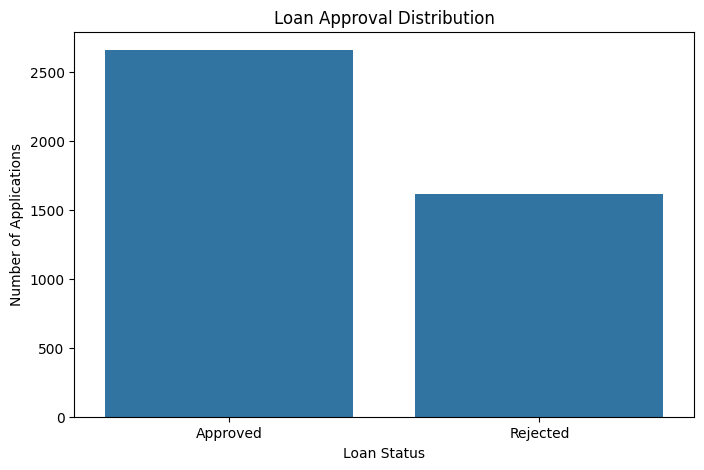

In [63]:
# Create a count plot
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='loan_status')

plt.title('Loan Approval Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applications')

plt.show()

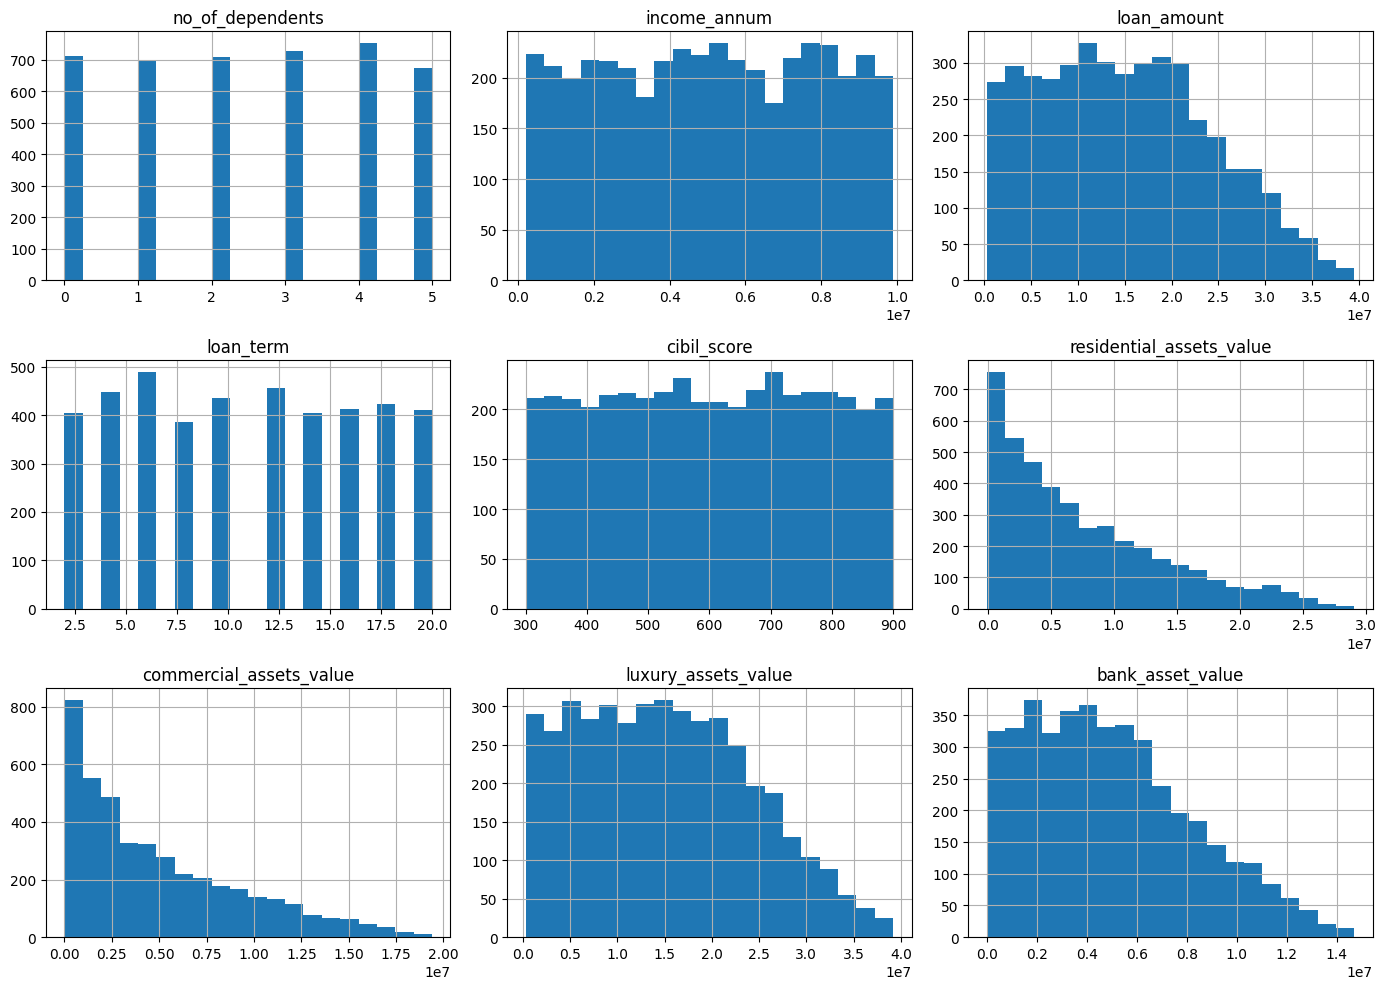

In [64]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Plot histograms for numerical columns
df[numerical_columns].hist(figsize=(14, 10), bins=20)

# Adjust spacing between graphs
plt.tight_layout()

plt.show()

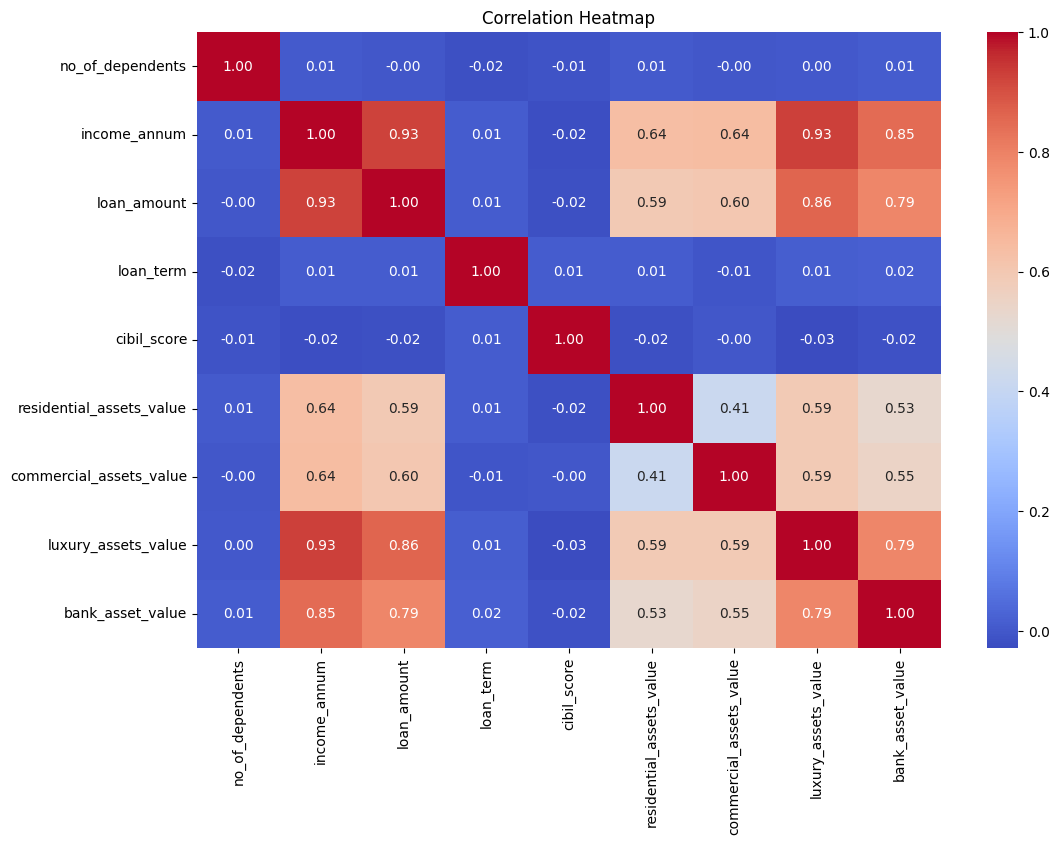

In [65]:
# Calculate correlations between numerical columns
correlation = df[numerical_columns].corr()

# Create a correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

In [66]:
# Convert loan status into lowercase text
df['loan_status'] = df['loan_status'].astype(str).str.strip().str.lower()

# Convert approval outcomes into binary values
df['loan_status'] = df['loan_status'].map({
    'approved': 1,
    'rejected': 0,
})

# Check the converted values
df['loan_status'].value_counts(dropna=False)

,count
loan_status,
1,2656
0,1613
